# C02-GN — GMM trên RFM + AOV + Diversity + QtyPerOrder (log1p + Standard + PCA 90%)

Thí nghiệm **C02-GN** (người chạy: An) theo chiến lược model. So với C01, **thêm QtyPerOrder** (avg_quantity_per_order — số lượng sản phẩm trung bình mỗi đơn).

## Params

In [1]:
FEATURES_C01 = ["Recency", "Frequency", "Monetary", "AOV", "Diversity"]
FEATURES = FEATURES_C01 + ["QtyPerOrder"]     # C02: thêm QtyPerOrder
PCA_VAR = 0.90
RANDOM_STATE = 42
N_INIT = 10
MAX_ITER = 300
TOL = 1e-3
REG_COVAR = 1e-6
INIT_PARAMS = "kmeans"
K_RANGE = range(2, 11)
COV_TYPES = ["full", "tied", "diag", "spherical"]
MIN_CLUSTER_FRAC = 0.01

## Import thư viện và đọc dữ liệu

In [2]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

warnings.filterwarnings("ignore", category=UserWarning)

def find(rel):
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())

DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figure"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

df = pd.read_csv(DATA, dtype={"CustomerID": "string"}).rename(columns={
    "avg_order_value": "AOV", "n_stock_codes": "Diversity",
    "avg_quantity_per_order": "QtyPerOrder", "observed_span_days": "Tenure"})
X = df[FEATURES].copy()
assert df["CustomerID"].is_unique and X.notna().all().all() and (X > 0).all().all()
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 6)


,Recency,Frequency,Monetary,AOV,Diversity,QtyPerOrder
count,4327.00,4327.00,4327.00,4327.00,4327.00,4327.0
mean,93.04,4.25,1944.95,372.40,61.49,227.4
std,99.98,7.64,8441.89,466.49,85.31,298.5
min,1.00,1.00,2.90,2.90,1.00,1.0
25%,18.00,1.00,301.52,175.47,16.00,93.0
50%,51.00,2.00,657.90,286.70,35.00,161.0
75%,143.00,5.00,1624.10,421.99,77.00,272.0
max,374.00,206.00,278748.02,14844.77,1784.00,7824.0


**Nhận xét:** Cùng 4.327 khách, 6 feature, không có giá trị ≤0 (đủ điều kiện log1p, kiểm tra `> 0` thay vì `>= 0` vì QtyPerOrder/AOV luôn dương).

## log1p, chuẩn hóa, PCA giữ 90% phương sai

In [3]:
X_scaled = Pipeline([("log1p", FunctionTransformer(np.log1p)), ("scaler", StandardScaler())]).fit_transform(X)
ev = PCA(svd_solver="full").fit(X_scaled).explained_variance_ratio_
cum = np.cumsum(ev)
n_pc = int(np.searchsorted(cum, PCA_VAR) + 1)
pca = PCA(n_components=n_pc, svd_solver="full").fit(X_scaled)
Z = pca.transform(X_scaled)
print(pd.DataFrame({"skew_raw": X.skew(), "skew_log1p": np.log1p(X).skew()}).round(2))
print("Phương sai tích lũy:", cum.round(4))
print(f"Số PC giữ lại: {n_pc} / {len(FEATURES)} (phương sai giữ {cum[n_pc-1]:.2%})")

             skew_raw  skew_log1p
Recency          1.25       -0.33
Frequency       11.95        1.21
Monetary        21.04        0.35
AOV             11.94       -0.00
Diversity        6.92       -0.24
QtyPerOrder      9.45       -0.38
Phương sai tích lũy: [0.5848 0.8207 0.9089 0.9721 0.9995 1.    ]
Số PC giữ lại: 3 / 6 (phương sai giữ 90.89%)


**Nhận xét:** Skew sau log1p đều về gần 0 (−0,38 đến 1,21). Cần **3/6 PC** để đạt 90% (giữ 90,89%) — cùng số PC với C01 (3/5) dù thêm 1 biến, cho thấy QtyPerOrder không tạo thêm hướng biến thiên độc lập đáng kể.

## Quét k × covariance_type

Chọn: full, k=7, BIC=39,264.1, Silhouette=0.1026, cụm nhỏ nhất=84


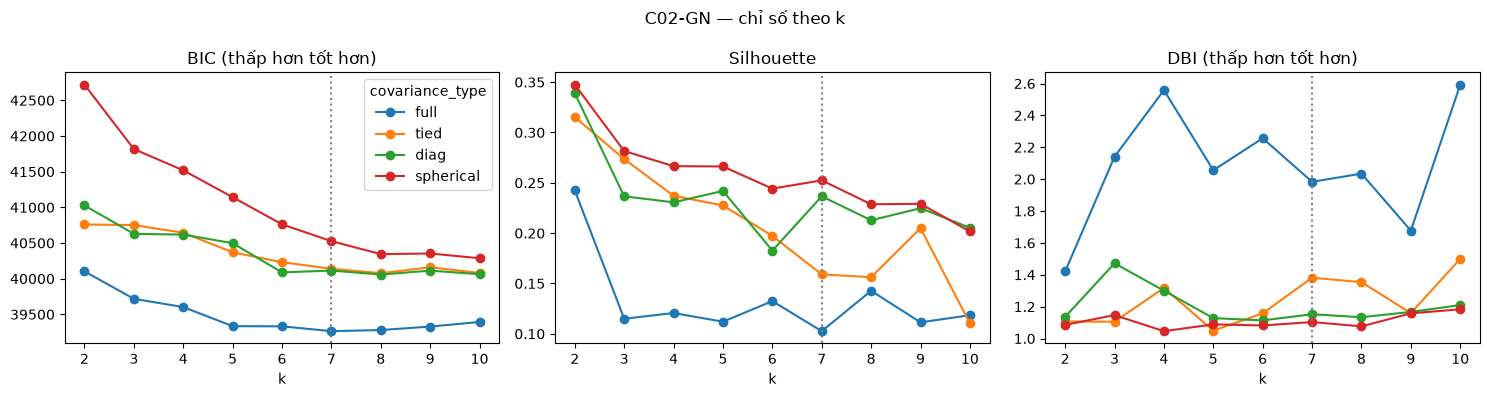

In [4]:
def sweep(Zs):
    rows = []
    for cov in COV_TYPES:
        for k in K_RANGE:
            gm = GaussianMixture(n_components=k, covariance_type=cov, n_init=N_INIT, max_iter=MAX_ITER, tol=TOL,
                                  reg_covar=REG_COVAR, init_params=INIT_PARAMS, random_state=RANDOM_STATE).fit(Zs)
            lab = gm.predict(Zs); sizes = np.bincount(lab, minlength=k)
            ok = len(np.unique(lab)) > 1
            rows.append({"covariance_type": cov, "k": k, "BIC": gm.bic(Zs), "AIC": gm.aic(Zs),
                         "Silhouette": silhouette_score(Zs, lab) if ok else np.nan,
                         "DBI": davies_bouldin_score(Zs, lab) if ok else np.nan,
                         "CHI": calinski_harabasz_score(Zs, lab) if ok else np.nan,
                         "min_cluster": int(sizes.min()), "converged": bool(gm.converged_)})
    return pd.DataFrame(rows)

def select(res, n):
    ok = res[res["converged"] & (res["min_cluster"] >= MIN_CLUSTER_FRAC * n)]
    return ok.loc[ok["BIC"].idxmin()]

res = sweep(Z)
best = select(res, len(X))
print(f"Chọn: {best['covariance_type']}, k={int(best['k'])}, BIC={best['BIC']:,.1f}, "
      f"Silhouette={best['Silhouette']:.4f}, cụm nhỏ nhất={int(best['min_cluster'])}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["BIC", "Silhouette", "DBI"]):
    for cov in COV_TYPES:
        s = res[res["covariance_type"] == cov]
        ax.plot(s["k"], s[col], marker="o", label=cov)
    ax.axvline(int(best["k"]), color="gray", ls=":")
    ax.set_xlabel("k"); ax.set_title(col + (" (thấp hơn tốt hơn)" if col in ("BIC", "DBI") else ""))
axes[0].legend(title="covariance_type")
plt.suptitle("C02-GN — chỉ số theo k")
plt.tight_layout(); plt.savefig(FIG / "gmm_metrics.png", dpi=150); plt.show()

**Nhận xét:** BIC thấp nhất ở `full`, k=7 (39.264,1), cụm nhỏ nhất 84 khách (≥ 1% quy tắc chọn).

## Train mô hình cuối

In [5]:
model = Pipeline([("log1p", FunctionTransformer(np.log1p)), ("scaler", StandardScaler()),
                   ("pca", PCA(n_components=n_pc, svd_solver="full")),
                   ("gmm", GaussianMixture(n_components=int(best["k"]), covariance_type=best["covariance_type"],
                                            n_init=N_INIT, max_iter=MAX_ITER, tol=TOL, reg_covar=REG_COVAR,
                                            init_params=INIT_PARAMS, random_state=RANDOM_STATE))]).fit(X)
gm = model["gmm"]
labels = gm.predict(Z)
proba = gm.predict_proba(Z)
assert (model[:-1].transform(X) == Z).all()
print("Hội tụ:", gm.converged_, "| số vòng EM:", gm.n_iter_)
print(pd.Series(labels).value_counts().sort_index().rename("Số khách"))
print("Silhouette:", round(silhouette_score(Z, labels), 4), "| DBI:", round(davies_bouldin_score(Z, labels), 4))

Hội tụ: True | số vòng EM: 41
0      84
1     467
2     630
3     619
4     448
5     695
6    1384
Name: Số khách, dtype: int64
Silhouette: 0.1026 | DBI: 1.9832


**Nhận xét:** 7 cụm, kích thước 84–1.384 khách — khá cân đối, hội tụ sau 41 vòng EM. Silhouette 0,1026 tương đương C01-GN (A02-GN gốc 0,0226; B02-GN 0,1041) — mức chồng lấn tương tự các GMM khác trong dự án.

## Đối chiếu C01-DB và B02-GN

Dựng lại C01 bằng GMM (cùng pipeline, bớt QtyPerOrder) để so trực tiếp bằng ARI.

In [6]:
X_c01 = X[FEATURES_C01]
Xs_c01 = Pipeline([("log1p", FunctionTransformer(np.log1p)), ("scaler", StandardScaler())]).fit_transform(X_c01)
cum_c01 = np.cumsum(PCA(svd_solver="full").fit(Xs_c01).explained_variance_ratio_)
n_pc_c01 = int(np.searchsorted(cum_c01, PCA_VAR) + 1)
Z_c01 = PCA(n_components=n_pc_c01, svd_solver="full").fit_transform(Xs_c01)
res_c01 = sweep(Z_c01); best_c01 = select(res_c01, len(X))
labels_c01 = GaussianMixture(n_components=int(best_c01["k"]), covariance_type=best_c01["covariance_type"],
                              n_init=N_INIT, max_iter=MAX_ITER, tol=TOL, reg_covar=REG_COVAR,
                              init_params=INIT_PARAMS, random_state=RANDOM_STATE).fit_predict(Z_c01)

print("Số PC: C02 =", Z.shape[1], "| C01 (GMM, dựng lại) =", Z_c01.shape[1])
print(f"C01 (GMM): {best_c01['covariance_type']}, k={int(best_c01['k'])}, BIC={best_c01['BIC']:,.1f}")
print(f"C02       : {best['covariance_type']}, k={int(best['k'])}, BIC={best['BIC']:,.1f}")
print("ARI (C02-GN vs C01 bằng GMM):", round(adjusted_rand_score(labels, labels_c01), 4))

Số PC: C02 = 3 | C01 (GMM, dựng lại) = 3
C01 (GMM): full, k=6, BIC=36,807.8
C02       : full, k=7, BIC=39,264.1
ARI (C02-GN vs C01 bằng GMM): 0.5424


**Nhận xét:** ARI so với C01 (dựng lại bằng GMM, cùng pipeline) = **0,5424** — khác biệt rõ rệt (số cụm đổi từ 6 lên 7), QtyPerOrder có đóng góp thật, không phải biến dư thừa như AOV ở C01.

## Hồ sơ cụm

In [7]:
prof = X.assign(cluster=labels).groupby("cluster").agg(
    customers=("Monetary", "size"), Recency=("Recency", "median"), Frequency=("Frequency", "median"),
    Monetary=("Monetary", "median"), AOV=("AOV", "median"), Diversity=("Diversity", "median"),
    QtyPerOrder=("QtyPerOrder", "median"), Monetary_sum=("Monetary", "sum"))
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof.drop(columns="Monetary_sum").round(1)

,customers,Recency,Frequency,Monetary,AOV,Diversity,QtyPerOrder,customer_share_pct,Monetary_share_pct
cluster,,,,,,,,,
0,84,4.0,23.5,13346.1,787.4,181.0,486.2,1.9,31.4
1,467,72.0,1.0,311.2,308.9,17.0,184.0,10.8,2.0
2,630,24.0,1.0,276.7,186.1,17.0,112.0,14.6,2.9
3,619,96.0,3.0,657.5,261.8,37.0,140.7,14.3,5.8
4,448,90.0,3.0,1291.4,547.4,56.5,364.8,10.4,11.6
5,695,275.0,1.0,226.8,207.5,13.0,103.0,16.1,2.7
6,1384,17.0,6.0,1782.1,313.9,85.0,182.6,32.0,43.6


**Nhận xét:** Cụm 0 (84 khách, 1,9%) là nhóm VIP rõ nhất: Frequency 23,5, Monetary 13.346, QtyPerOrder 486,2 — chiếm **31,4% Monetary** dù chưa tới 2% khách. Cụm 6 (1.384 khách, 32%) là nhóm hoạt động ổn định (Recency 17, Frequency 6) chiếm 43,6% Monetary — hai cụm này cộng lại đã chiếm 75% doanh thu. Các cụm 1,2,5 là khách mua 1 lần, Monetary thấp (227–311), Recency cao (72–275 ngày) — có vẻ đã rời bỏ. GMM với QtyPerOrder tách được nhiều mức rõ ràng hơn so với DBSCAN cùng feature set (C01-DB chỉ tách 2 nhóm).

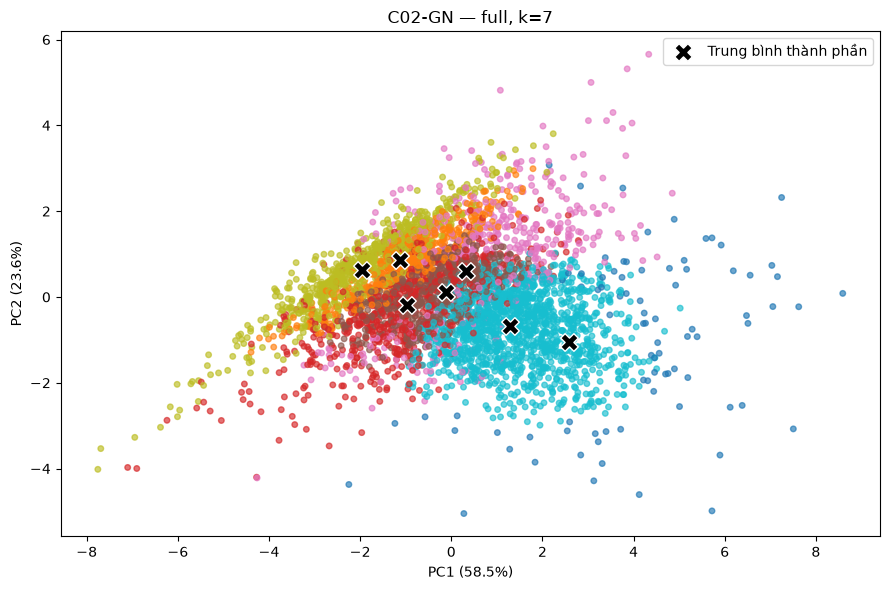

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))
centers = gm.means_
ax.scatter(Z[:, 0], Z[:, 1], c=labels, cmap="tab10", s=16, alpha=0.65)
ax.scatter(centers[:, 0], centers[:, 1], c="black", marker="X", s=160, edgecolors="white", label="Trung bình thành phần")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.set_title(f"C02-GN — {best['covariance_type']}, k={int(best['k'])}")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "gmm_clusters_pca.png", dpi=150); plt.show()

**Nhận xét:** 7 cụm là các vùng chồng lấn trên PC1–PC2, không tách bạch — khớp Silhouette thấp đã thấy ở trên, nhưng hồ sơ cụm (trên) vẫn cho thấy phân khúc có ý nghĩa kinh doanh rõ.

## Lưu kết quả

In [9]:
res.to_csv(OUT / "gmm_c02_grid.csv", index=False)
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels, "max_proba": proba.max(axis=1).round(4)}) \
    .to_csv(OUT / "gmm_c02_labels.csv", index=False)
joblib.dump(model, "gmm_c02_model.pkl")
params = {"experiment": "C02-GN", "features": FEATURES,
          "feature_sources": {"AOV": "avg_order_value", "Diversity": "n_stock_codes", "QtyPerOrder": "avg_quantity_per_order"},
          "transform": "log1p", "scaler": "StandardScaler",
          "pca_variance": PCA_VAR, "n_components": n_pc, "pca_variance_kept": float(cum[n_pc - 1]),
          "covariance_type": best["covariance_type"], "k": int(best["k"]), "bic": float(best["BIC"]),
          "silhouette": float(best["Silhouette"]), "dbi": float(best["DBI"]),
          "ari_vs_c01_gmm": float(adjusted_rand_score(labels, labels_c01))}
json.dump(params, open(OUT / "gmm_c02_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['gmm_c02_grid.csv', 'gmm_c02_labels.csv', 'gmm_c02_params.json']


**Nhận xét kết luận C02-GN:** Thêm QtyPerOrder làm GMM chia **7 cụm** cân đối (84–1.384 khách) với phân khúc rõ ràng — 1 nhóm VIP (1,9% khách, 31,4% Monetary), 1 nhóm hoạt động ổn định (32% khách, 43,6% Monetary), và vài nhóm khách 1 lần có vẻ đã rời bỏ. Khác C01 thật sự (ARI=0,54). Đây là kết quả GMM cân đối và có ý nghĩa nhất tính đến nay trong nhóm C, cùng hướng tốt với B03-KM (RFM + Yeo-Johnson) — nên đưa cả hai vào so sánh cuối cùng để chọn mô hình báo cáo.